In [13]:
import sys
RE_path = './'
sys.path.insert(1, RE_path)


In [14]:
import numpy as np
from matplotlib import pyplot as plt
import RE
import importlib
importlib.reload(RE)
from RE import *
import RESolver as solver
importlib.reload(solver)
import scipy.constants as const

# Example Solution using SPARC-like Parameters #

In [15]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.5 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax

# Constants
R0 = 1.85 # [m]
a = 0.57 # [m]
Zeff = 1
T = 10 # eV
ne = 3e20 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    
# Initial Conditions
jp0, rmax = getj0(8.7e6,128)
jr0 = np.zeros_like(jp0)

constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

Configure the solver

In [20]:
import RESolver as solver
importlib.reload(solver)

out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.4,
                        RE_sources=[0,0,1,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=0.1*3e8,
                        nprint=500,
                        verbose=True,comp_scale_factor=1e8)



nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 0,iTritBeta = 0, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000391

Seed Ir(t=dt) [MA] = 2.35e-06

step = 500, time [ms] = 0.20, Ip [MA] = 7.52, E/Ec [-] = 1407.64
step = 1000, time [ms] = 0.39, Ip [MA] = 6.80, E/Ec [-] = 1367.97
step = 1500, time [ms] = 0.59, Ip [MA] = 6.22, E/Ec [-] = 1323.34
step = 2000, time [ms] = 0.78, Ip [MA] = 5.72, E/Ec [-] = 1270.39
step = 2500, time [ms] = 0.98, Ip [MA] = 5.28, E/Ec [-] = 1206.46
step = 3000, time [ms] = 1.17, Ip [MA] = 4.89, E/Ec [-] = 1128.65
step = 3500, time [ms] = 1.37, Ip [MA] = 4.53, E/Ec [-] = 1031.83
step = 4000, time [ms] = 1.56, Ip [MA] = 4.21, E/Ec [-] = 908.75
step = 4500, time [ms] = 1.76, Ip [MA] = 3.92, E/Ec [-] = 755.29
step = 5000, time [ms] = 1.95, Ip [MA] = 3.66, E/Ec [-] = 585.81
step = 5500, time [ms] = 2.15, Ip [MA] = 3.42, E/Ec [-] = 450.26
step = 6000, time [ms] = 2.35, Ip [MA] = 3.21, E/Ec [-] = 345.93
step = 6500, time

Show results

(0.0, 9.14079498765389)

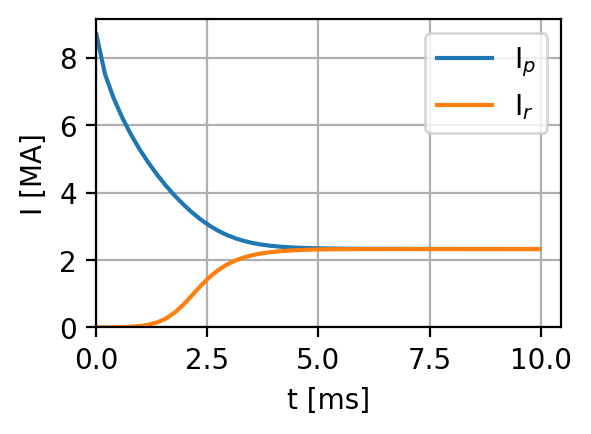

In [21]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)



Final Profile

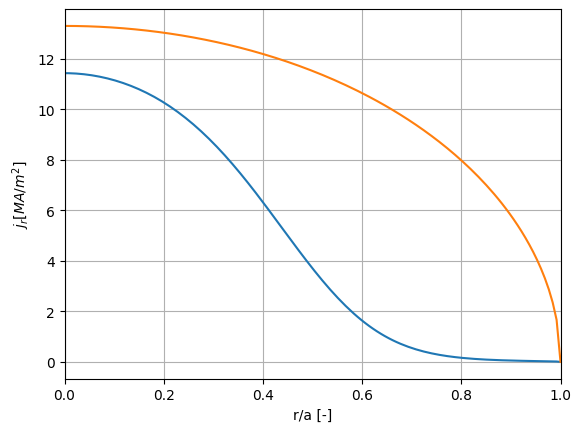

In [22]:
r = np.linspace(0,rmax,out['jr'].shape[0])

plt.plot(r/rmax,out['jr']/1e6)
plt.plot(r/rmax,jp0/1e6)
plt.xlabel('r/a [-]')
plt.ylabel('$j_r [MA/m^2]$')
plt.xlim([0,1])
plt.grid()

In [ ]:
out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.4,
                        RE_sources=[0,0,1,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=0.1*3e8,
                        nprint=500,
                        verbose=True,comp_scale_factor=1e8)

# Check Compton Function

Text(0.5, 0, 'E$^*$ [-]')

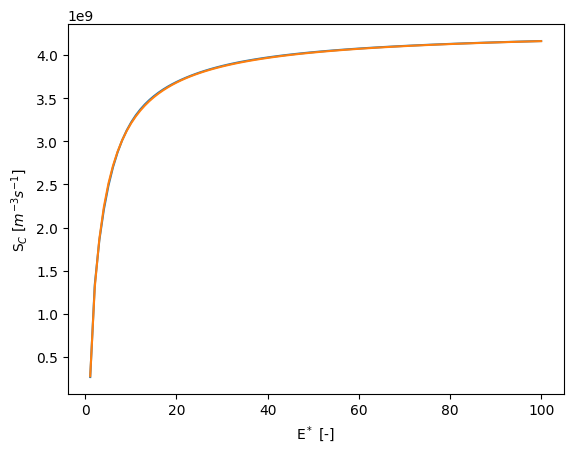

In [12]:
ne = 1e20
E_star = np.linspace(1.1,100,100)
Sc = getComptonSource(E_star,ne,device='SPARC-P') # m-3/s
Sc_analy = ne * analy_compton_source(E_star) # m-3/s

plt.plot(E_star,Sc)
plt.plot(E_star,Sc_analy)
plt.ylabel('S$_C$ [$m^{-3} s^{-1}$]')
plt.xlabel('E$^*$ [-]')